In [1]:
import pandas as pd
import numpy as np
import importlib
import ot
import numpy as np
import scipy.stats as st
import ruptures as rpt

from scipy.stats import ks_2samp
from sklearn.metrics import silhouette_score

from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

import w1_tree as wt
import geotopics_plots as gtp

import plotly.express as px

import subfield_tree as sft

In [2]:
PATH = "../data_clean/"
mode = "individual"


df_country = pd.read_csv("../data/Floriana_country_info.csv").rename(columns={"alpha-2": "alpha2"})
df_topics = pd.read_csv("../data_clean/df_topics.csv")
df_topics.subfield_id = df_topics.subfield_id.astype(int)

df_cs = pd.read_csv(PATH+"df_country_subfield_roll_5y.csv", index_col=[0, 1, 2]).dropna(how="all")
df_cs.columns = df_cs.columns.astype(int)

year_list = df_cs.index.get_level_values(1).unique().sort_values().to_list()
country_list = df_cs.index.get_level_values(0).unique().sort_values().to_list()

df_prob = df_cs.div(df_cs.sum(axis=1), axis=0)

df_subfield = (
    pd.read_csv(PATH+"df_topics.csv")
    [["subfield_id", "subfield_name", "field_id", "field_name", "domain_id", "domain_name"]]
    .drop_duplicates()
    .sort_values(["domain_id", "field_id", "subfield_id"])
)
df_subfield.subfield_id = df_subfield.subfield_id.astype(int)
subfield_tree = sft.SubfieldTree(df_subfield)

df_dist_year = pd.read_csv(PATH+"df_dist_year.csv", index_col=[0, 1, 2])

In [3]:
import numpy as np

def gini(sizes, normalize=False):
    """
    Gini coefficient of cluster sizes.
    0 = all clusters equal size, higher = more unequal.

    sizes     : array-like of positive cluster sizes (e.g. [20, 15, 10, 3, 2])
    normalize : if True, multiply by K/(K-1) so the maximum possible value is 1
                regardless of the number of clusters K.
    """
    x = np.sort(np.asarray(sizes, dtype=float))   # ascending
    K = len(x)
    if K == 0 or x.sum() == 0:
        raise ValueError("sizes must be non-empty and sum to > 0")
    if K == 1:
        return 0.0

    i = np.arange(1, K + 1)
    g = (2 * np.sum(i * x)) / (K * x.sum()) - (K + 1) / K

    return g * K / (K - 1) if normalize else g


def gini_from_labels(labels, normalize=False):
    """Gini of cluster sizes directly from a label vector (one label per year)."""
    _, counts = np.unique(labels, return_counts=True)
    return gini(counts, normalize=normalize)

In [4]:
def stability_plot(country, country_name, ax, mode="individual", vmax=0, vmin=-0.5):
    year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
    

    df_plot = (
        -df_dist_year
        .xs((country, mode), level=(0, 1))
        .pivot(columns="year_to", values="distance")
    )

    inactive_years = ~df_plot.columns.isin(year_list_active)

    df_plot.loc[inactive_years, :] = None
    df_plot = df_plot.T
    df_plot.loc[inactive_years, :] = None
    # df_plot.loc[:, inactive_years] = None
    # df_plot.loc[inactive_years, inactive_years] = None
    # display(df_dist_year.xs((country, "individual"), level=(0, 1)).loc[year_list_active].query("year_to in @year_list_active"))

    dist_std = df_dist_year.xs((country, "individual"), level=(0, 1)).loc[year_list_active].query("year_to in @year_list_active").distance.std().round(2)
    dist_max = df_dist_year.xs((country, "individual"), level=(0, 1)).loc[year_list_active].query("year_to in @year_list_active").distance.max().round(2)

    hm = sns.heatmap(df_plot, ax=ax, cbar=False, cmap=cmap,)

    # cbar = hm.collections[0].colorbar
    # cbar.ax.tick_params(labelrotation=-90, labelsize=12)
    # cbar.ax.locator_params(nbins=4)

    step=6
    x_ticks = range(0, len(df_plot.columns), step)
    y_ticks = range(0, len(df_plot.index), step)

    ax.annotate(
        f"STD = {dist_std}\nMax = {dist_max}",
        xy=(48, 3),
        # xytext=(0.98, 0.35), textcoords='axes fraction',
        ha='right', va='top',
        fontsize=15, color='black',
        bbox=dict(boxstyle='round', fc='white', ec='black', alpha=0.8)
    )

    ax.set_xticks(x_ticks)
    ax.set_xticklabels(df_plot.columns[::step], rotation=45, ha="right")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(df_plot.index[::step], rotation=0)
    ax.tick_params(labelsize=16)

    ax.set_title(country_name, fontsize=18)
    # ax.tick_params(labelsize=16)
    ax.set_xlabel("")
    ax.set_ylabel("")

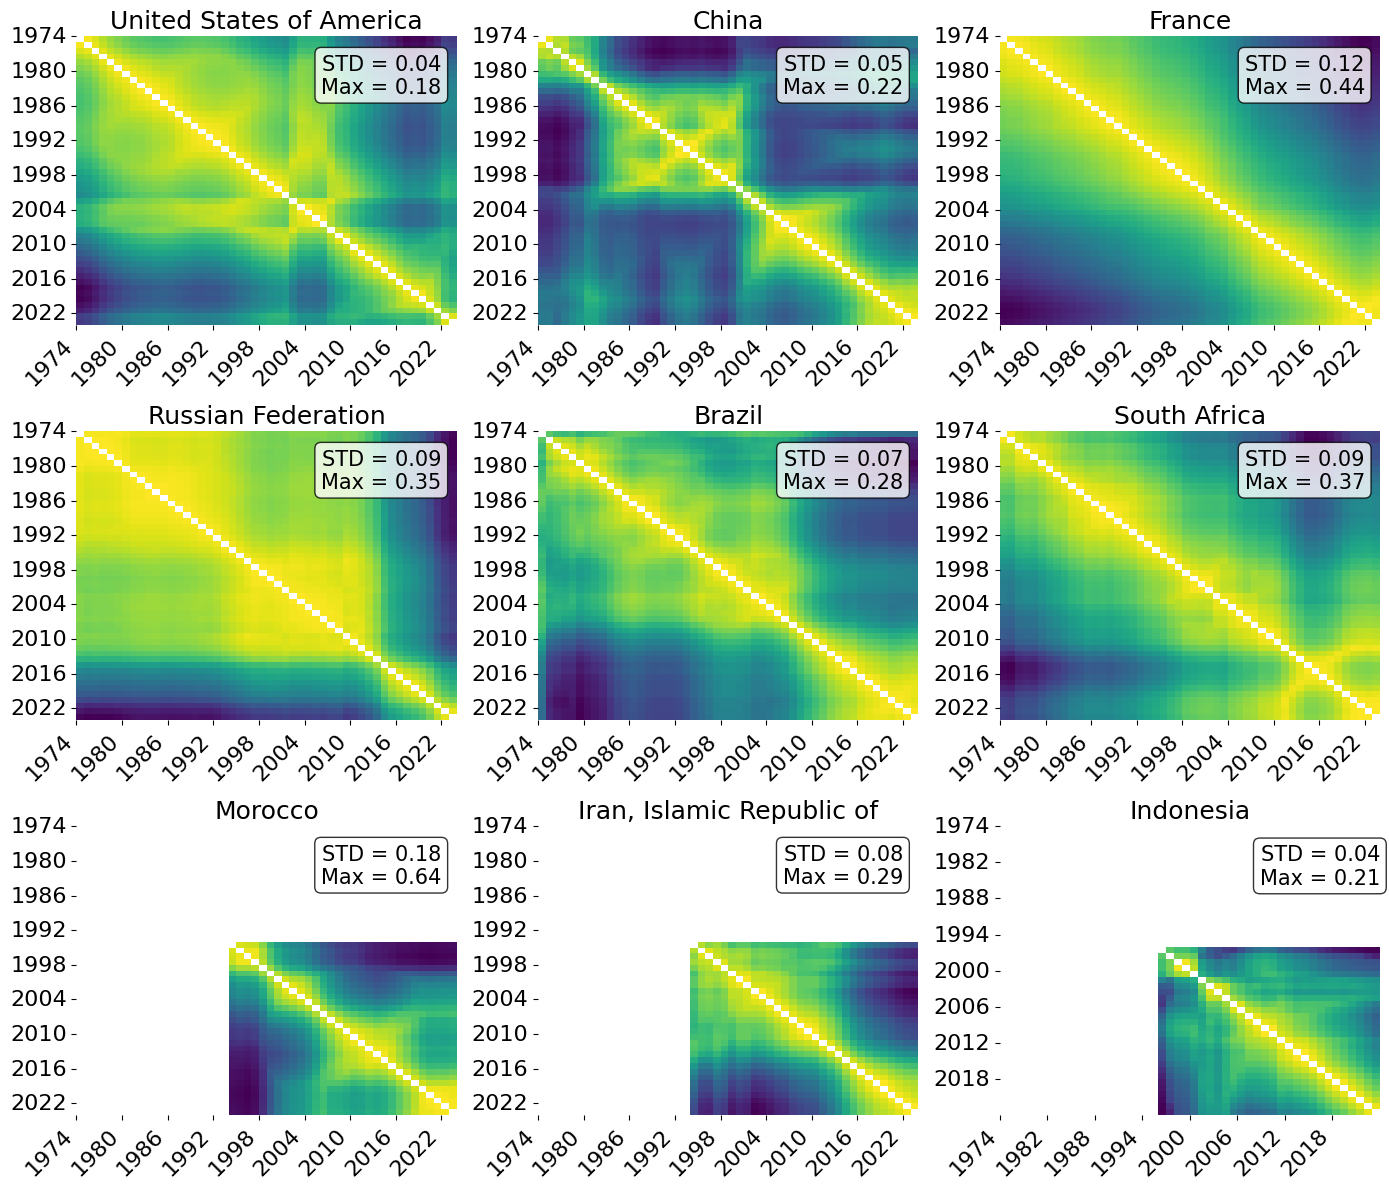

In [5]:
country_list_short=["US", "CN", "FR", "RU", "BR", "ZA","MA","IR","ID"]
countries = list(df_country.query("alpha2 in @country_list_short")[["alpha2", "name"]].set_index("alpha2").loc[country_list_short].to_dict()["name"].items())

cmap = "viridis"

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

axes = axes.flatten()

for ax, (code, name) in zip(axes, countries):
    stability_plot(code, name, ax)

plt.tight_layout()
plt.savefig(f"../images/stability_v4.jpg", dpi=1000, bbox_inches='tight')

In [6]:
# mode = "individual"

# df_dist_yearly = (
#     df_dist_year
#     .xs((mode), level=(1))
#     .loc[(country_list, slice(None)), :]
#     .reset_index()
#     .query("year_from == (year_to - 1)")
# )

# df_active_list = [] 
# for country in country_list:
#     year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
#     # inactive_years = ~df_plot.columns.isin(year_list_active)
#     df_active_list.append(
#         df_dist_yearly
#         .query("country == @country")
#         .query("(year_to in @year_list_active) and (year_from in @year_list_active)")
#     )

# df_dist_yearly = pd.concat(df_active_list, axis=0).sort_values(["country", "year_to", "year_from"]).reset_index(drop=True)

In [7]:
def get_kernel(df_dist):
    N = len(df_dist.index)
    D = df_dist.values
    D = (D + D.T) / 2
    np.fill_diagonal(D, 0)

    # 1. Переводим матрицу расстояний в матрицу сходства (Ядро)
    # Подберите медианное расстояние в качестве сигмы (gamma = 1 / (2 * sigma^2))
    gamma = 1.0 / (2 * (np.median(D) ** 2))
    K = np.exp(-gamma * (D ** 2))

    return K

def calculate_total_cost(cost_object, bkps, pen = 0):
    total_cost = 0
    start = 0
    for bkp in bkps:
        total_cost += cost_object.error(start, bkp)
        start = bkp
    return total_cost + pen * len(bkps)

def get_optimal_nbkp(algo, max_bkps, cutoff=0.5):
    n_bkps_range = range(1, max_bkps)
    costs = []
    for n_bkps in n_bkps_range:
        # Предсказываем фиксированное число точек
        bkps = algo.predict(n_bkps=n_bkps)
        
        # ИСПРАВЛЕНО: Считаем суммарную стоимость через интервальные ошибки bkps
        current_cost = calculate_total_cost(algo.cost, bkps)
        costs.append(current_cost)

    costs_diff = np.diff(np.array(costs))
    cost_indices = np.where(np.abs(costs_diff) < cutoff)[0]
    
    n_bkps_idx = 0 if len(cost_indices) == 0 else cost_indices[0]
    return n_bkps_range[n_bkps_idx] if n_bkps_idx != 0 else 0

def get_algo(df_dist, min_size=1):
    K = get_kernel(df_dist)

    w, V = np.linalg.eigh(K)
    w = np.clip(w, 0, None)                # clip small negative values
    X = V * np.sqrt(w) 

    algo = rpt.KernelCPD(kernel="linear", min_size=min_size).fit(X)
    return algo

def get_change_points(df_dist, min_size=1, cutoff=0.5, ):
    algo = get_algo(df_dist, min_size)
    max_bkps = int(np.floor(len(df_dist.index) / min_size))
    n_bkps = get_optimal_nbkp(algo, max_bkps, cutoff)
    if n_bkps == 0:
        return []
    years = df_dist.index.tolist()
    result_indices = algo.predict(n_bkps=n_bkps)
    detected_years = [years[idx] for idx in result_indices[:-1]]
    return detected_years

## Possible questions

- What countries are more or less “inert”? Does it depend on size, on longitude of scientific tradition? Are there any obvious patterns?
- What kind of changes affect different countries the most? Classify the discovered events into groups (if possible for some list of countries) and see
- What fields are changing? How distant the changes are?
— Does shock in a specific country affect the global system: how individual shocks affect the groups (see how we can define groups, maybe like top 10 collaborators or new collaborators)
- What kinds of events affect different kinds of changes in terms of structure?

## Kernel CPD

\begin{align}
c(y_{a:b}) &= \sum_{t=a}^{b-1} k(y_t, y_t) \;-\; \frac{1}{b-a} \sum_{s=a}^{b-1} \sum_{t=a}^{b-1} k(y_s, y_t) \\[8pt]
\hat{\mathcal{T}} &= \arg\min_{\mathcal{T}} \; \sum_{k=0}^{K} c\big(y_{t_k:t_{k+1}}\big) + \text{pen}\cdot K \qquad \text{s.t. } t_{k+1} - t_k \ge m
\end{align}

## Silhouette Score

\begin{align}
a(i) &= \frac{1}{|C_i| - 1} \sum_{\substack{j \in C_i \\ j \neq i}} d(i, j) \\[6pt]
b(i) &= \min_{k \neq i} \frac{1}{|C_k|} \sum_{j \in C_k} d(i, j) \\[6pt]
s(i) &= \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \\[6pt]
SilhouetteScore &= \frac{1}{N} \sum_{i=1}^{N} s(i)
\end{align}

## Chamfer distance

$$
Chamfer(A, B) = \sum_{a \in A} \min_{b \in B} (a - b)^2 + \sum_{b \in B} \min_{a \in A} (a - b)^2
$$

- allows to track similarity of close but not exactly the same years
- the square helps to punish not the same years more

In [8]:
def chamfer_distance(A, B, squared=True):
    A = np.asarray(A)
    B = np.asarray(B)
    # print(A)
    distances = np.abs(A[:, None] - B[None, :])

    if squared:
        distances = distances ** 2

    return (
        distances.min(axis=1).mean()
        + distances.min(axis=0).mean()
    )

In [9]:
def calculate_modularity(adjacency_matrix, partition):
    """
    Calculate modularity given an adjacency matrix and a partition.

    Parameters
    ----------
    adjacency_matrix : array-like, shape (n, n)
        Adjacency matrix of an undirected network.
    partition : array-like, shape (n,)
        Community label for each node.

    Returns
    -------
    float
        Modularity Q.
    """
    A = np.asarray(adjacency_matrix, dtype=float)
    partition = np.asarray(partition)

    degrees = A.sum(axis=1)
    m2 = A.sum()

    if m2 == 0:
        return 0.0

    # Expected edge weights under the configuration model
    expected = np.outer(degrees, degrees) / m2

    # Nodes in the same community
    same_community = partition[:, None] == partition[None, :]

    Q = np.sum((A - expected) * same_community) / m2

    return Q

In [10]:
def gini(x):
    x = np.asarray(x, dtype=float)

    if np.any(x < 0):
        raise ValueError("Gini requires non-negative values.")

    if len(x) == 0 or x.sum() == 0:
        return 0.0

    x = np.sort(x)
    n = len(x)

    return (2 * np.sum(np.arange(1, n + 1) * x)) / (n * x.sum()) - (n + 1) / n

def hoover(x):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return np.nan
    if np.any(x < 0):
        raise ValueError("Values must be non-negative.")
    if x.sum() == 0:
        return 0.0

    shares = x / x.sum()
    return 0.5 * np.abs(shares - 1 / len(x)).sum()

def entropy_inequality(x):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return np.nan
    if np.any(x < 0):
        raise ValueError("Values must be non-negative.")
    if x.sum() == 0:
        return 0.0
    if len(x) == 1:
        return 0.0

    p = x / x.sum()
    p = p[p > 0]

    entropy = -np.sum(p * np.log(p))

    return 1 - entropy / np.log(len(x))


def coefficient_of_variation(x):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return np.nan

    mean = x.mean()

    if mean == 0:
        return 0.0 if np.all(x == 0) else np.nan

    return x.std(ddof=0) / mean

In [11]:
def get_partition(bkps_year, n, year_list_active):
    partition = np.zeros(n)
    val = 0
    prev_idx = 0
    for year in bkps_year[1:]:
        year_idx = year_list_active.index(year)
        partition[prev_idx:year_idx] = val
        val += 1
        prev_idx = year_idx
    return partition

In [12]:
def null_chamfer(B_n, t_start, t_end, n_perm=1000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_perm):
        rand_bkps = sorted(rng.choice(np.arange(t_start, t_end + 1), size=len(B_n), replace=False))
        # print(rand_bkps)
        # print(np.diff(B_n), np.diff(rand_bkps))
        vals.append(chamfer_distance(B_n, np.append(B_n, rand_bkps)))
    return np.array(vals)

# def null_wasserstein(B_n, t_start, t_end, n_perm=2000, seed=0):
#     rng = np.random.default_rng(seed)
#     vals = []
#     for _ in range(n_perm):
#         rand_bkps = sorted(rng.choice(np.arange(t_start, t_end + 1), size=len(B_n), replace=False))
#         # print(rand_bkps)
#         # print(np.diff(B_n), np.diff(rand_bkps))
#         vals.append(wasserstein_distance(np.diff(B_n), np.append(np.diff(B_n), np.diff(rand_bkps))))
#     return np.array(vals)

def null_costs(algo, n_bkps, n_max, n_perm=2000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_perm):
        rand_bkps = sorted(rng.choice(np.arange(1, n_max+1), size=n_bkps, replace=False))
        # print(rand_bkps)
        # print(np.diff(B_n), np.diff(rand_bkps))
        vals.append(algo.cost.sum_of_costs(rand_bkps))
    return np.array(vals)

def null_silhouette(B_n, D, n, year_list_active, t_start, t_end, n_perm=1000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_perm):
        rand_bkps = sorted(rng.choice(np.arange(t_start, t_end + 1), size=len(B_n), replace=False))
        # print(rand_bkps)
        # print(np.diff(B_n), np.diff(rand_bkps))
        partition = get_partition(rand_bkps, n, year_list_active)
        vals.append(silhouette_score(D, partition, metric="precomputed"))
    return np.array(vals)

# score: where does the real distance fall in the null?
# z = (d_real - null.mean()) / null.std()   or   p = (null <= d_real).mean()

In [13]:
def get_country_data(country, algo, year_list_active, K, D, n_bkps_range = None):

    if n_bkps_range is None:
        n_bkps_range = np.arange(len(year_list_active))[1:]

    bkps_prev = []
    df_list = []
    
    K_zero = K
    for i in range(K.shape[0]):
        K_zero[i, i] = 0
        
    for n_bkps in n_bkps_range:
    # Предсказываем фиксированное число точек
        bkps = algo.predict(n_bkps=n_bkps)
        bkps_year = np.array([year_list_active[0]] + [year_list_active[bkp] for bkp in bkps[:-1]] + [year_list_active[-1]])
        
        bkps_year_diff = np.diff(bkps_year)

        partition = get_partition(bkps_year, K_zero.shape[0], year_list_active)

        if n_bkps == 1:
            bkps_prev = bkps_year
        else:
            # statistic, p_value = ks_2samp(sample_prev, sample)
            # print(bkps[:-1], bkps_prev[:-1], len([bkp for bkp in bkps_prev if bkp in bkps]), len(bkps_prev))
            # len([bkp for bkp in bkps_prev if bkp in bkps]) / len(bkps_prev)
            intersect_prev = [bkp for bkp in bkps_prev[1:-1] if bkp in bkps_year[1:-1]]
            union_prev = list(set(bkps[1:-1]).union(bkps_prev[1:-1]))
            # non_intersect_prev = [bkp for bkp in bkps[1:-1] if bkp not in bkps_prev[1:-1]]

            chamfer_null = null_chamfer(bkps_prev[1:-1], year_list_active[1], year_list_active[-2])
            # costs_null = null_costs(algo, n_bkps, n_bkps_range[-1])
            # chamfer_value = chamfer_distance(bkps_prev[1:-1], bkps_year[1:-1])
            chamfer_value = chamfer_distance(bkps_year[1:-1], bkps_prev[1:-1])

            silhouette = silhouette_score(D, partition, metric="precomputed")
            # silhouette_null = null_silhouette(bkps_prev, D, K_zero.shape[0], year_list_active, year_list_active[0], year_list_active[-1])
            # wasserstein = wasserstein_distance(np.diff(bkps_prev), bkps_year_diff)
            # wasserstein_null = null_wasserstein(bkps_prev, 1974, 2023)
            df_list.append({
                "country": country,
                "n_bkps": n_bkps,
                "n_bkps_prev": n_bkps - 1,
                "n_bkps_ratio": (n_bkps - 1) / len(year_list_active),
                #
                "chamfer_distance": chamfer_value,
                "chamfer_rank": (np.sum(chamfer_null <= chamfer_value) + 1) / (len(chamfer_null) + 1),
                # "wasserstein": wasserstein, 
                # "wasserstein_rank": (np.sum(wasserstein_null <= wasserstein) + 1) / (len(wasserstein_null) + 1),
                "jaccard": len(intersect_prev) / len(union_prev),
                # for previous n_bkps
                "gini_period": gini(np.diff(bkps_prev)),
                # "hoover_period": hoover(np.diff(bkps_prev)),
                # "norm_entropy": entropy_inequality(np.diff(bkps_prev)),
                # "variation_coef": coefficient_of_variation(np.diff(bkps_prev)),
                # for previous n_bkps
                "period_max": max(np.diff(bkps_prev)),
                "max_period": np.max(np.diff(bkps_prev)),
                "min_period": np.min(np.diff(bkps_prev)),
                "median_period": np.median(np.diff(bkps_prev)),
                # for previous n_bkps
                "silhouette": silhouette,
                # "silhouette_rank": (np.sum(silhouette_null <= silhouette) + 1) / (len(silhouette_null) + 1),
                "modularity": calculate_modularity(K_zero, partition),
                # 
                "cost": algo.cost.sum_of_costs(bkps),
                # "cost_rank": (np.sum(costs_null <= algo.cost.sum_of_costs(bkps)) + 1) / (len(costs_null) + 1),
                "bkps": bkps_prev
            })
            bkps_prev = bkps_year
    return pd.json_normalize(df_list)


In [14]:
country = "CN"
n_bkps_max = 20

df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
df_dist_test = df_dist_test.loc[year_list_active, year_list_active]

K = get_kernel(df_dist_test)
algo = get_algo(df_dist_test)

df_country_data = get_country_data(country, algo, year_list_active, K, df_dist_test.fillna(0).values, n_bkps_range=np.arange(1, 20))

In [15]:
(
    df_country_data
    .query("chamfer_distance < 2")
    # .query("dissimilarity_ratio < scale")
    .assign(
        bkps_dist = lambda df: [df.n_bkps.iloc[0]] + df.n_bkps.diff().to_list()[1:]
    )
    .query("bkps_dist > 1")
)

,country,n_bkps,n_bkps_prev,n_bkps_ratio,chamfer_distance,chamfer_rank,jaccard,gini_period,period_max,max_period,min_period,median_period,silhouette,modularity,cost,bkps,bkps_dist
2,CN,4,3,0.06,1.583333,0.023976,0.333333,0.198980,19,19,8,11.0,0.530203,0.088288,2.952280,"[1974, 1982, 2001, 2015, 2023]",4.0
5,CN,7,6,0.12,1.690476,0.039960,0.333333,0.332362,17,17,3,6.0,0.432257,0.061265,1.820275,"[1974, 1981, 1984, 2001, 2004, 2013, 2017, 2023]",2.0
8,CN,10,9,0.18,0.611111,0.009990,0.444444,0.214286,9,9,2,5.0,0.360697,0.026744,1.270946,"[1974, 1980, 1982, 1985, 1991, 1996, 2001, 200...",2.0


In [140]:
n_bkps = 4

bkps = algo.predict(n_bkps=n_bkps)
bkps_year = np.array(year_list_active)[bkps[:-1]]

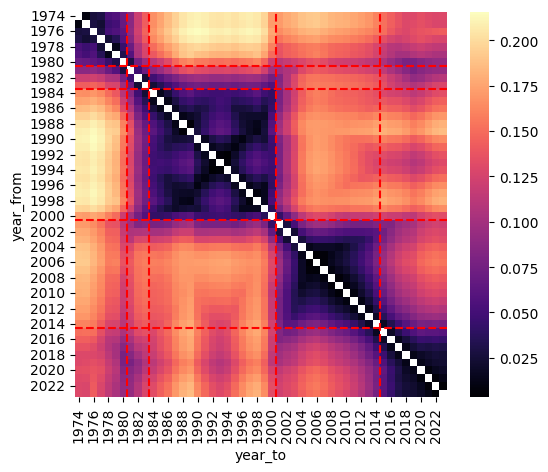

In [141]:
fig, ax = plt.subplots(figsize=(6, 5))

detected_years_full = [year_list_active[0]] + bkps_year + [year_list_active[-1]]


sns.heatmap(
    df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance").loc[year_list_active, year_list_active],
    ax=ax, cbar=True, cmap="magma",
)

# df_K = pd.DataFrame(K, index=year_list_active, columns=year_list_active)
# sns.heatmap(
#     1 - df_dist_test,
#     ax=ax, cbar=True, cmap="magma",
# )
peak_years = bkps_year
for year in peak_years:
    if year not in year_list_active:
        continue
    i = year_list_active.index(year)
    ax.axvline(x=i, color='red', linestyle='--', label=f'Tipping Point: {year}')
    ax.axhline(y=i, color='r', linestyle='--', label=f'Tipping Point: {year}')


In [92]:
# plt.subplots(figsize=(10, 4))
# plt.plot(df_country_data.n_bkps_prev, df_country_data.cost_rank)
# # plt.axhline(0.1, color="red")
# plt.grid(alpha=0.3)
# plt.title(f"{country}: Cost rank")

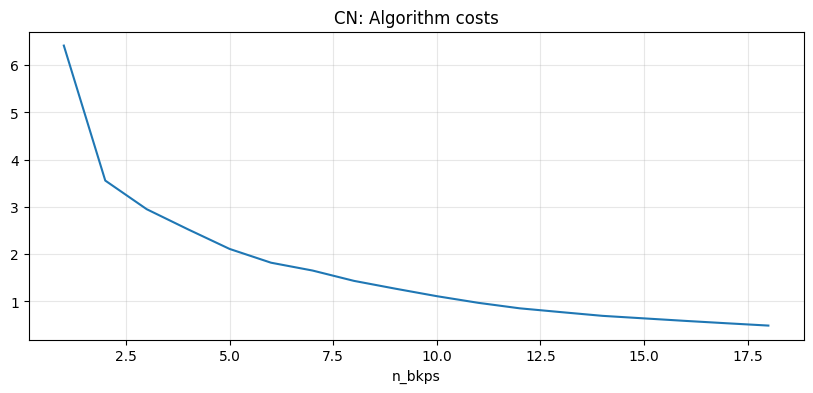

In [139]:
plt.subplots(figsize=(10, 4))
plt.plot(df_country_data.n_bkps_prev, df_country_data.cost)
# plt.axhline(0.1, color="red")
plt.grid(alpha=0.3)
plt.xlabel("n_bkps")
plt.title(f"{country}: Algorithm costs")
plt.show()

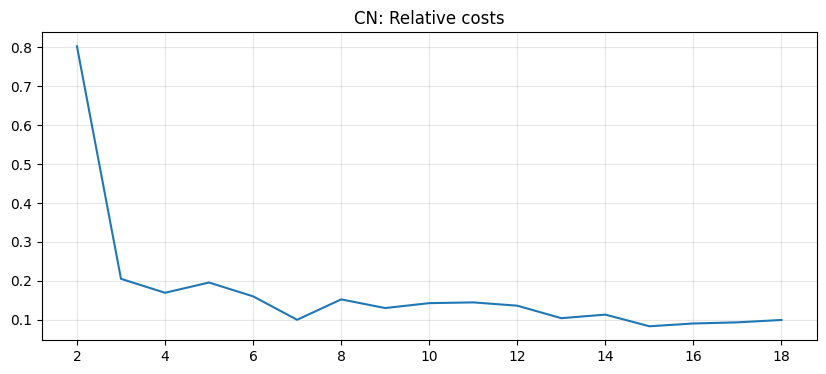

In [94]:
plt.subplots(figsize=(10, 4))
plt.plot(df_country_data.n_bkps_prev, np.abs(df_country_data.cost.diff()) / df_country_data.cost)
# plt.axhline(0.1, color="red")
plt.grid(alpha=0.3)
plt.title(f"{country}: Relative costs")
plt.show()

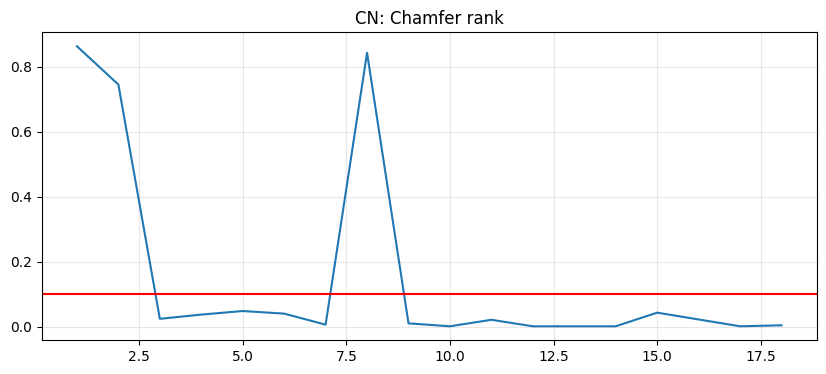

In [95]:
plt.subplots(figsize=(10, 4))
plt.plot(df_country_data.n_bkps_prev, df_country_data.chamfer_rank)
plt.axhline(0.1, color="red")
plt.grid(alpha=0.3)
plt.title(f"{country}: Chamfer rank")
plt.show()

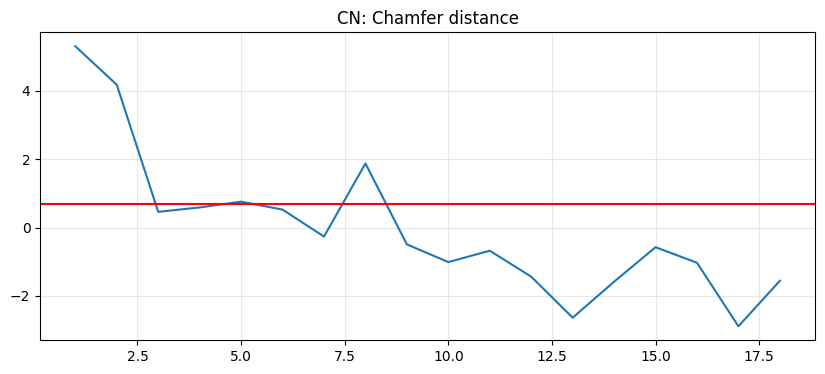

In [96]:
plt.subplots(figsize=(10, 4))
plt.plot(df_country_data.n_bkps_prev, np.log(df_country_data.chamfer_distance))
plt.axhline(np.log(2), color="red")
plt.grid(alpha=0.3)
plt.title(f"{country}: Chamfer distance")
plt.show()

In [97]:
bkps_array = np.zeros((len(df_country_data.index), len(year_list_active)))

for idx in df_country_data.index:
    for year in df_country_data.loc[idx, "bkps"]:
        bkps_array[idx, year_list_active.index(year)] = 1

In [98]:
# agg_vals = []
# agg_vals2 = []
# agg_vals3 = []
# for idx in df_country_data.index:
#     # print(bkps_array[idx, :] == 1)
#     # print(bkps_array[idx:, :].sum(axis=0).shape)
#     # print((bkps_array[idx:, :].sum(axis=0)[bkps_array[idx, :] == 1] / bkps_array[idx:, 0].sum(axis=0))[1:-1])
#     tmp = (bkps_array[idx:, :].sum(axis=0)[bkps_array[idx, :] == 1] / bkps_array[idx:, 0].sum(axis=0))[1:-1]
#     res = np.median(tmp)
#     # print(res)
#     agg_vals.append(res)
#     agg_vals2.append(np.mean(tmp))
#     agg_vals3.append(np.mean(tmp**2))
#     # print()

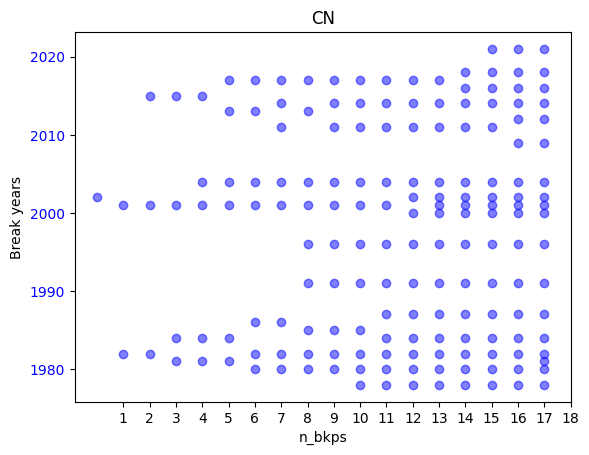

In [99]:
fig, ax1 = plt.subplots()

for idx in df_country_data.index:
    alpha = 0.5
    # if  ((idx == 0 ) or (agg_vals[idx-1] < 0.85)) and (agg_vals[idx] >= 0.85):
    #     alpha = 0.4
    # if ((idx == 0 ) or (agg_vals[idx-1] < 0.9)) and (agg_vals[idx] >= 0.9):
    #     alpha = 0.6
    # if ((idx == 0 ) or (agg_vals[idx-1] < 0.95)) and (agg_vals[idx] >= 0.95):
    #     alpha = 0.9
    
    # alpha = 0.5 if (agg_vals[idx-1] < 0.85) and (agg_vals[idx] >= 0.85) else 0.3
    ax1.scatter([idx]*(len(df_country_data.loc[idx, "bkps"])-2), df_country_data.loc[idx, "bkps"][1:-1], alpha=alpha, color="blue")

ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylabel("Break years")
ax1.set_xticks(ticks=np.arange(1, len(agg_vals)+1))

# # Second Y-axis
# ax2 = ax1.twinx()
# ax2.plot(np.arange(1, len(agg_vals)+1), agg_vals, color='red')
# ax2.plot(np.arange(1, len(agg_vals)+1), agg_vals2, color='red', linestyle="--")
# ax2.plot(np.arange(1, len(agg_vals)+1), agg_vals3, color='red', linestyle=":")
# # ax2.scatter(np.arange(len(agg_vals)), agg_vals, color='red')
# ax2.set_ylabel('Aggregated index', color='red')
# ax2.tick_params(axis='y', labelcolor='red')
# ax2.set_ylim(0, 1.1)
# ax2.axhline(0.9, color="grey")

ax1.set_xlabel("n_bkps")
ax1.set_title(country)
plt.show()



# All countries -- 

In [16]:
country_list = list(df_dist_year.reset_index().country.unique())

In [17]:
df_list = []

for country in tqdm(country_list):
    try:
        df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
        year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
        if len(year_list_active) <= 20:
            continue
        df_dist_test = df_dist_test.loc[year_list_active, year_list_active]
        K = get_kernel(df_dist_test)
        algo = get_algo(df_dist_test)
        df_country_data = get_country_data(country, algo, year_list_active, K, df_dist_test.fillna(0).values)

        df_list.append(
            df_country_data
            # .query("chamfer_distance < 2")
            .assign(
                chamfer2=lambda df: (
                    (df["chamfer_distance"] > 2)
                    & ~(df["chamfer_distance"].shift(1) > 2)
                )
            )
            # .query("bkps_dist > 1")
            # .query("n_bkps_prev == 1")
        )
    except Exception as e:
        print(country, e)

# df_n_bkps = (
#     pd.concat(df_list)
#     .assign(
#         # silhouette_quantile = lambda df: df.groupby('n_bkps_prev')['silhouette'].rank(pct=True),
#         chamfer_rolling=lambda df: df.chamfer_distance.rolling(3).mean()
#     )
#     # .merge(df_country[["alpha2", "alpha-3", "name", "region", "sub-region"]], left_on="country", right_on="alpha2")
#     # .drop("country", axis=1)
#     # .rename(columns={"alpha-3": "country"})
# )

  7%|▋         | 14/206 [00:04<00:55,  3.43it/s]


KeyboardInterrupt: 

In [ ]:
df_n_bkps = (
    pd.concat(df_list)
    .assign(
        silhouette_quantile = lambda df: df.groupby('n_bkps_prev')['silhouette'].rank(pct=True),
        chamfer_rolling=lambda df: df.chamfer_distance.rolling(3).mean(),
        first_bkp = lambda df: [bkps[1] for bkps in df.bkps]
    )
)

In [113]:
px.box(df_n_bkps.query("n_bkps_prev <= 20").assign(
    log_chamfer = lambda df: np.log(df.chamfer_distance),
    # chamfer_rolling=lambda df: df.chamfer_distance.rolling(3).sum()
    ), x="n_bkps_prev", y=["chamfer_rank"], title="Chamfer distance by number of breakpoints")

Text(0.5, 1.0, 'Costs vs number of breakpoints')

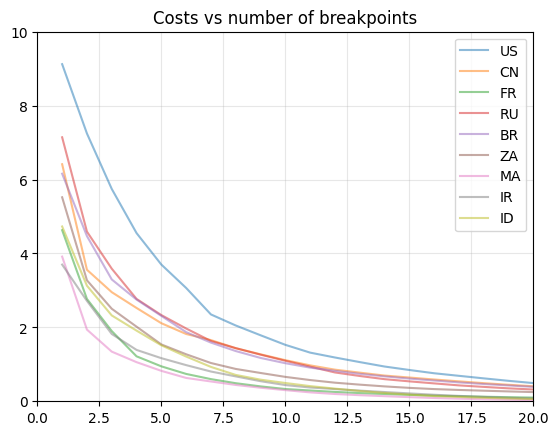

In [116]:
for country in country_list_short:
    plt.plot(df_n_bkps.query(f"country == '{country}'").n_bkps_prev, df_n_bkps.query(f"country == '{country}'").cost, label=country, alpha=0.5)
plt.ylim(0, 10)
plt.xlim(0, 20)
plt.grid(alpha=0.3)
plt.legend()
plt.title("Costs vs number of breakpoints")

In [122]:
df_n_bkps.query("chamfer2 == 1")

,country,n_bkps,n_bkps_prev,n_bkps_ratio,chamfer_distance,chamfer_rank,jaccard,gini_period,period_max,max_period,min_period,median_period,silhouette,modularity,cost,bkps,chamfer2,silhouette_quantile,chamfer_rolling,first_bkp
0,AE,2,1,0.047619,42.000000,0.667333,0.000000,0.300000,16,16,4,10.0,0.363242,0.083924,3.726504,"[2003, 2007, 2023]",True,0.090909,NaN,2007
0,AM,2,1,0.038462,18.000000,0.554446,0.500000,0.180000,17,17,8,12.5,0.427475,0.154933,2.752083,"[1998, 2015, 2023]",True,0.285714,6.034211,2015
3,AM,5,4,0.153846,3.600000,0.298701,0.375000,0.352000,11,11,2,4.0,0.279741,0.064095,0.689986,"[1998, 2009, 2015, 2017, 2021, 2023]",True,0.012987,5.533333,2009
0,AR,2,1,0.020000,243.500000,0.802198,0.000000,0.173469,33,33,16,24.5,0.549752,0.136748,4.676938,"[1974, 2007, 2023]",True,0.844156,81.193889,2007
7,AR,9,8,0.160000,2.180556,0.304695,0.375000,0.176871,10,10,4,4.0,0.353275,0.041361,0.647431,"[1974, 1980, 1984, 1988, 1998, 2004, 2008, 201...",True,0.571429,2.502646,1980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8,UZ,10,9,0.391304,4.900000,0.276723,0.500000,0.454545,10,10,1,1.0,0.142852,-0.004660,0.054188,"[2001, 2011, 2012, 2013, 2016, 2017, 2018, 201...",True,0.025974,1.712037,2011
0,VE,2,1,0.023256,62.000000,0.547453,0.000000,0.119048,26,26,16,21.0,0.496345,0.155743,4.268495,"[1981, 1997, 2023]",True,0.597403,20.697691,1997
0,VN,2,1,0.043478,19.500000,0.605395,0.000000,0.090909,13,13,9,11.0,0.324935,0.040345,4.773615,"[2001, 2010, 2023]",True,0.012987,6.516067,2010
0,ZA,2,1,0.020000,98.000000,0.606394,0.000000,0.030612,26,26,23,24.5,0.500336,0.161736,5.519228,"[1974, 1997, 2023]",True,0.623377,32.697691,1997


In [132]:
var = "n_bkps_prev"

# country_group = ["alpha2", "name", "region", "sub-region"]

df_plot = (
    df_n_bkps
    # .query("(n_bkps_prev <= 15) and (n_bkps_prev > 5)")
    # .query("(n_bkps_prev == 1)")
    .query("(chamfer2 == 1) and (n_bkps_prev > 1)")
    # .groupby(["country"], as_index=False)[var].min()
    .sort_values("n_bkps_prev")
    .drop_duplicates("country")
    # .merge(df_n_bkps[["country", "n_bkps_prev", var]], on=["country", var])
    # .assign(n_divisions=df_n_bkps.groupby(["country"], as_index=False)[var].count()[var].to_list())
    # .groupby(["country"], as_index=False)["n_bkps_prev"].min()
    # .merge(df_n_bkps, on=["country", "n_bkps_prev"])
    .merge(df_country[["alpha2", "alpha-3", "name", "region", "sub-region"]], left_on="country", right_on="alpha2")
    .drop("country", axis=1)
    .rename(columns={"alpha-3": "country"})
    # .query("modularity >= 0")
    
)

# display(df_plot)

fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="gini_period",
    hover_name="country",
    hover_data=["alpha2", "n_bkps_ratio", "n_bkps_prev", "gini_period", "silhouette", "min_period", "max_period", "median_period"],
    color_continuous_scale="Viridis",
    projection="natural earth",
    # title="Silhouette score: all countries"
)
fig.show()

In [107]:
px.scatter(df_plot, x="first_bkp", y="silhouette", hover_name="name", color="sub-region", hover_data=["alpha2"], title="Year of first breakpoint vs Silhouette")

In [179]:
# fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
# ax2.hist(df_plot.silhouette, bins=25, color="salmon")
# ax2.grid(alpha=0.3)
# ax2.set_title("How pronounced is the structure? (Silhouette)")

# ax4.hist(df_plot.hoover_period, bins=25, color="salmon")
# ax4.grid(alpha=0.3)
# ax4.set_title("How unbalanced are period sizes? (Hoover)")

# ax1.hist(df_plot.n_bkps_prev, bins=25, color="salmon")
# ax1.grid(alpha=0.3)
# ax1.set_title("How many change points?")

# ax3.hist(df_plot.max_period, bins=25, color="salmon")
# ax3.grid(alpha=0.3)
# ax3.set_title("What is the longest defined period?")

# plt.show()

In [180]:
# country_list_test = ["RU", "US", "RO"]
# df_plot.query("alpha2 in @country_list_test")[["alpha2", "n_bkps", "n_bkps_prev", "gini_period", "hoover_period", "max_period", "min_period"]]

In [181]:
# fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 4))
# ax1.hist(df_plot.gini_period, bins=25, color="salmon")
# ax1.grid(alpha=0.3)
# ax1.set_title("gini_period")

# ax2.hist(df_plot.hoover_period, bins=25, color="salmon")
# ax2.grid(alpha=0.3)
# ax2.set_title("hoover_period")

# ax3.hist(df_plot.norm_entropy, bins=25, color="salmon")
# ax3.grid(alpha=0.3)
# ax3.set_title("norm_entropy")

# ax4.hist(df_plot.variation_coef, bins=25, color="salmon")
# ax4.grid(alpha=0.3)
# ax4.set_title("variation_coef")

plt.show()

In [182]:
# df_plot[["gini_period", "hoover_period", "norm_entropy", "variation_coef"]].corr()

In [108]:
df_plot[["gini_period", "silhouette", "max_period"]].corr()

,gini_period,silhouette,max_period
gini_period,1.000000,-0.279693,0.491729
silhouette,-0.279693,1.000000,0.250255
max_period,0.491729,0.250255,1.000000


In [ ]:
px.box(df_plot.sort_values(["region", "sub-region"]), x="sub-region", y="silhouette", hover_data=["name", "alpha2", "n_bkps_prev"], points="all",
       title="Silhouette by sub-region")

In [185]:
px.scatter(df_plot, x="silhouette", y="gini_period", hover_data=["alpha2", "name"], color="region")

# One country -- novelty based segmentation

\begin{align}
\text{Checkerboard kernel:}\quad
C_L &= \begin{pmatrix} \mathbf{1}_{L\times L} & -\mathbf{1}_{L\times L} \\ -\mathbf{1}_{L\times L} & \mathbf{1}_{L\times L} \end{pmatrix} \\[8pt]
s(t) &= \frac{1}{2L^2} \sum_{i,j} \big(C_L\big)_{ij}\, K_{t-L+i-1,\; t-L+j-1}, \qquad t = L, \dots, N-L \\[10pt]
\text{Equivalently:}\quad
s(t) &= \frac{1}{2}\left(\bar K_{LL}^{(t)} + \bar K_{RR}^{(t)}\right) - \bar K_{LR}^{(t)} \\[8pt]
\hat{\mathcal{T}} &= \{\, t \;:\; s(t) > s(t-1),\; s(t) \ge s(t+1),\; \text{prominence}(t) \ge \delta,\; |t - t'| \ge L \;\; \forall\, t' \in \hat{\mathcal{T}} \,\}
\end{align}

In [18]:
def novelty(K, L):
    """
    Boundary strength for each boundary position t = 1..n-1.
    Returns an array of length n-1, where s[i] is the boundary at t = i + 1.
    L = half-window size (≈ blur width). Windows are truncated at the ends.
    """
    n = K.shape[0]
    s = np.empty(n - 1)
    for i, t in enumerate(range(1, n)):
        a = max(0, t - L)
        b = min(n, t + L)
        left = slice(a, t)
        right = slice(t, b)
        within = 0.5 * (K[left, left].mean() + K[right, right].mean())

        across = K[left, right].mean()

        s[i] = within - across
    return s

In [19]:
def get_country_bkps(country, df_dist, novelty_window=5):
    D = df_dist.copy().fillna(0).values
    K = 1 - D

    s = novelty(K, L=novelty_window)   # try L around the blur width


    is_peak = (s[1:-1] > s[:-2]) & (s[1:-1] > s[2:])
    peaks = np.where(is_peak)[0] + 1   # shift back to original indice

    left  = s[peaks] - s[peaks - 1]    # backward difference
    right = s[peaks + 1] - s[peaks]    # forward difference

    peak_strength = s[peaks]
    peak_suddenness = np.abs(left) + np.abs(right)

    peaks_filtered = peaks

    # peaks_filtered = []
    # for i, peak in enumerate(peaks):
    #     if (peak_strength[i] >= 0.01) and (peak_suddenness[i] >= 0.001):
    #         if (i >= 1) and (peak - peaks[i-1] <= 2):
    #             if (np.abs(left[i]) - np.abs(right[i-1])) <= 0.001:
    #                 continue
    #         peaks_filtered.append(peak)
    # peaks_filtered = np.array(peaks_filtered)
    left  = s[peaks_filtered] - s[peaks_filtered - 1]    # backward difference
    right = s[peaks_filtered + 1] - s[peaks_filtered]    # forward difference

    peak_strength = s[peaks_filtered]
    peak_suddenness = np.abs(left) + np.abs(right)
    
    peak_years = df_dist.index[peaks_filtered+1]
    peak_years_full = [df_dist.index[0]] + list(peak_years) + [df_dist.index[-1]]
    peak_years_diff = np.diff(peak_years_full)

    partition = get_partition(peak_years_full, len(df_dist.index.to_list()), df_dist.index.to_list())

    country_stats = {
        "country": country,
        "s_median": np.median(s),
        "s_mean": np.min(s),
        "s_min": np.min(s),
        "s_max": np.max(s),
        "s_std": np.std(s),
        "s_unstable": np.mean(np.abs(np.diff(s))),
        "n_bkps": peaks.shape[0],
        "gini": gini(np.diff(peak_years_full)),
        "silhouette": silhouette_score(D, partition)
    }

    df_country_bkps = pd.DataFrame([peak_years, peak_strength, peak_suddenness, peak_years_diff[:-1], peak_years_diff[1:]],
                                   index=["year", "strength", "suddenness", "prev_period", "post_period"]).T.assign(country=country)
    return country_stats, df_country_bkps, s

In [188]:
country = "RU"

df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
if 1974 in year_list_active:
    year_list_active.remove(1974)
df_dist_test = df_dist_test.loc[year_list_active, year_list_active]

stat_dict, df_country_bkps, s = get_country_bkps(country, df_dist_test, novelty_window=5)

s_norm = (s - s.min()) / (s.max() - s.min())

x = np.linspace(0, 1, len(s))
left = list(np.diff(s)) + [0]
right = [0] + list(np.diff(s))

dx = np.diff(x)
dy = np.diff(s)
tv = np.sum(np.sqrt(dx**2 + dy**2))

l = np.hypot(dx, dy)                      # длины звеньев
phi = np.unwrap(np.arctan2(dy, dx))       # углы звеньев
dphi = np.diff(phi)                       # поворот в внутренних вершинах
ds = (l[:-1] + l[1:]) / 2

k_turn = dphi / ds  

np.nansum((np.abs(np.atan(left) - np.atan(right))))

np.float64(0.1652519273772498)

In [189]:
k_turn.shape

(46,)

In [190]:
from scipy.interpolate import make_smoothing_spline
spl = make_smoothing_spline(x, s, lam=0.00001)   # larger lam = smoother
s_smooth = spl(x)
curvature = spl.derivative(2)(x) / (1 + spl.derivative(1)(x)**2)**1.5

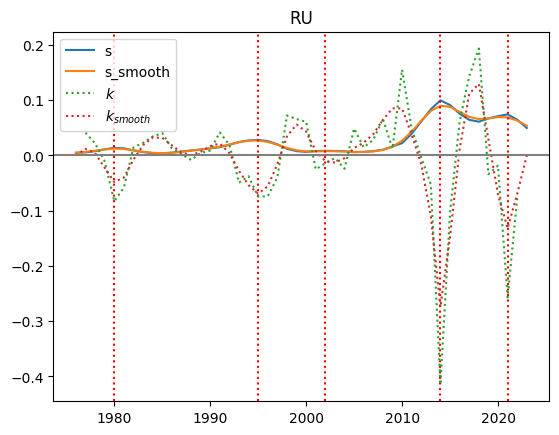

In [193]:
plt.plot(year_list_active[1:], s, label="s")
plt.plot(year_list_active[1:], s_smooth, label="s_smooth")
# plt.plot(year_list_active[1:], s_norm, label="s_norm")
for year in df_country_bkps.year:
    plt.axvline(year, color="red", linestyle=":")
plt.title(country)
# plt.plot(year_list_active[1:-1], np.diff(s_norm), label=r"$\Delta s$")
# plt.scatter(year_list_active[2:-1], k_turn / 50, label=r"$k$")
plt.plot(year_list_active[2:-1], k_turn / 100, label=r"$k$", linestyle=":")
plt.plot(year_list_active[1:], curvature / 100, label=r"$k_{smooth}$", linestyle=":")
plt.plot()
plt.axhline(0, color="grey")
plt.legend()

In [194]:
x = np.linspace(0, 1, len(s))

In [195]:
dx = np.diff(np.linspace(0, 1, len(s)))
dy = np.diff(s)
tv = np.sum(np.sqrt(dx**2 + dy**2))

In [196]:
left = list(np.diff(s)) + [0]
right = [0] + list(np.diff(s))

np.nansum((np.abs(np.atan(left) - np.atan(right))))

np.float64(0.1652519273772498)

In [197]:
np.cumsum(np.abs(np.atan(left) - np.atan(right)))

array([0.00042013, 0.00228959, 0.00330471, 0.00381851, 0.00761344,
       0.01031652, 0.01098574, 0.01203237, 0.0135819 , 0.01540679,
       0.01599632, 0.01610693, 0.01649252, 0.01668008, 0.01708215,
       0.01903299, 0.0199697 , 0.02233401, 0.02406327, 0.02747091,
       0.03102844, 0.03314777, 0.03684895, 0.03990737, 0.04266629,
       0.04381739, 0.04446843, 0.04469005, 0.04579054, 0.04799292,
       0.04864657, 0.04993635, 0.05309665, 0.05371403, 0.06432363,
       0.06980086, 0.07032224, 0.07608919, 0.10069987, 0.10787234,
       0.11244628, 0.12021957, 0.12935288, 0.13101735, 0.13189614,
       0.14477353, 0.15020764, 0.16525193])

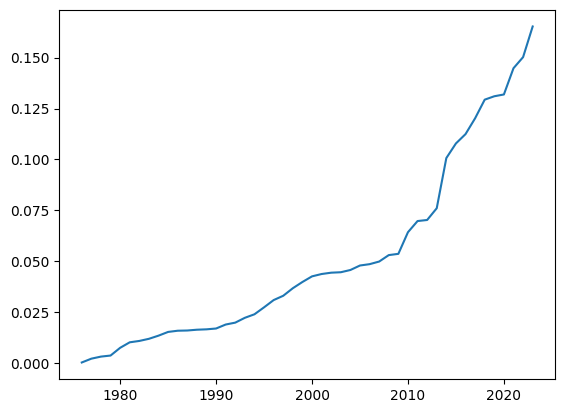

In [198]:
plt.plot(year_list_active[1:], np.cumsum(np.abs(np.atan(left) - np.atan(right))))

In [199]:
df_country_bkps

,year,strength,suddenness,prev_period,post_period,country
0,1980.0,0.013660,0.003795,5.0,15.0,RU
1,1995.0,0.028093,0.003408,15.0,7.0,RU
2,2002.0,0.008214,0.000651,7.0,12.0,RU
3,2014.0,0.099528,0.024612,12.0,7.0,RU
4,2021.0,0.074163,0.012878,7.0,2.0,RU


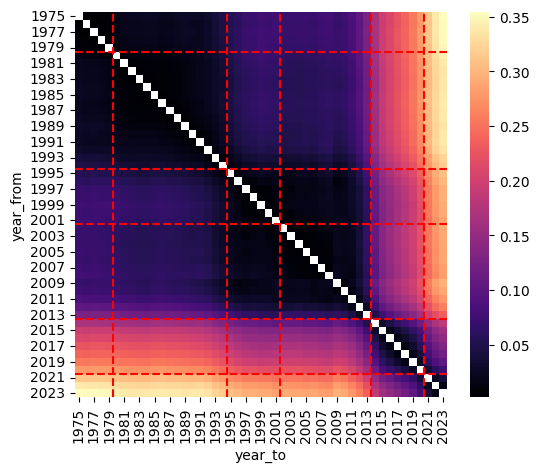

In [200]:
fig, ax = plt.subplots(figsize=(6, 5))

detected_years_full = [year_list_active[0]] + df_country_bkps.year.to_list() + [year_list_active[-1]]


sns.heatmap(
    df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance").loc[year_list_active, year_list_active],
    ax=ax, cbar=True, cmap="magma",
)

# df_K = pd.DataFrame(K, index=year_list_active, columns=year_list_active)
# sns.heatmap(
#     1 - df_dist_test,
#     ax=ax, cbar=True, cmap="magma",
# )
peak_years = df_country_bkps.year.to_list()
for year in peak_years:
    if year not in year_list_active:
        continue
    i = year_list_active.index(year)
    ax.axvline(x=i, color='red', linestyle='--', label=f'Tipping Point: {year}')
    ax.axhline(y=i, color='r', linestyle='--', label=f'Tipping Point: {year}')


In [201]:
partition = np.zeros(len(year_list_active))
val = 0
prev_idx = 0
for year in peak_years:
    year_idx = year_list_active.index(year)
    partition[prev_idx:year_idx] = val
    val += 1
    prev_idx = year_idx
partition

array([0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 2., 2., 2., 2., 2., 2., 2., 3., 3., 3., 3., 3., 3., 3.,
       3., 3., 3., 3., 3., 4., 4., 4., 4., 4., 4., 4., 0., 0., 0.])

In [202]:
detected_years_full = [year_list_active[0]] + list(peak_years) + [year_list_active[-1]]
n_periods = len(detected_years_full)-1

period_distances = np.full((n_periods, n_periods), np.nan)

prev_year = year_list_active[0]
for i, year_from in enumerate(detected_years_full[:-1]):
    for j, year_to in enumerate(detected_years_full[:-1]):
        if j < i:
            continue
        period_distances[j, i] = period_distances[i, j] = df_dist_test.loc[year_from : detected_years_full[i+1], year_to : detected_years_full[j+1]].mean().mean()

df_period_distance = pd.DataFrame(period_distances, index=detected_years_full[:-1], columns=detected_years_full[:-1])

<Axes: >

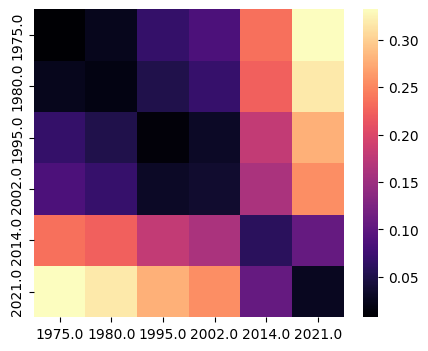

In [203]:
fig, ax = plt.subplots(figsize=(5, 4))

sns.heatmap(
    df_period_distance,
    ax=ax, cbar=True, cmap="magma",
)

# Compare curves

In [204]:
"""
Анализ и сравнение кривых y = f(x) по небольшому числу точек.
Кривая рассматривается как ломаная: никаких производных и сглаживания.
Нужен только numpy.
"""
import numpy as np

_trapz = getattr(np, "trapezoid", None) or np.trapz


# ---------- 1. Нормировка осей ----------
def normalize(x, y, x_range, y_range):
    """Приводит оси к [0, 1]. Для сравнения двух кривых используйте ОДНИ И ТЕ ЖЕ диапазоны."""
    xn = (np.asarray(x, float) - x_range[0]) / (x_range[1] - x_range[0])
    yn = (np.asarray(y, float) - y_range[0]) / (y_range[1] - y_range[0])
    return xn, yn


# ---------- 2. Профиль поворота и кривизна ----------
def turning_profile(x, y):
    dx, dy = np.diff(x), np.diff(y)
    seg_angle = np.arctan2(dy, dx)          # угол каждого звена (функция поворота)
    seg_len = np.hypot(dx, dy)
    theta = np.diff(seg_angle)              # угол поворота в внутренних вершинах (рад)
    k = theta / ((seg_len[:-1] + seg_len[1:]) / 2)   # дискретная кривизна в вершинах
    s = np.concatenate([[0], np.cumsum(seg_len)])    # длина дуги до каждой точки
    return dict(seg_angle=seg_angle, seg_len=seg_len, theta=theta, k=k, s=s)


def find_kinks(x, theta, thr_deg=15):
    """Вершины, где поворот по модулю больше порога (в градусах) = излом.
    Возвращает индексы вершин в исходном массиве x (внутренние вершины 1..n-2)."""
    idx = np.where(np.abs(np.degrees(theta)) > thr_deg)[0] + 1
    return idx


def passport(x, y, thr_deg=15):
    """Набор чисел, описывающих кривую."""
    p = turning_profile(x, y)
    kinks = find_kinks(x, p["theta"], thr_deg)
    L = p["s"][-1]
    C = np.hypot(x[-1] - x[0], y[-1] - y[0])
    return {
        "n_points": len(x),
        "n_kinks": len(kinks),
        "kink_x": x[kinks],
        "kink_angle_deg": np.degrees(p["theta"][kinks - 1]),
        "tortuosity L/C": L / C,
        "total_turning (sum|theta|)": np.abs(p["theta"]).sum(),
        "inflections (sign changes of theta)": int(
            np.sum(np.diff(np.sign(p["theta"][p["theta"] != 0])) != 0)
        ),
        "TV(y) (sum|dy|)": np.abs(np.diff(y)).sum(),
        "max|k|": np.abs(p["k"]).max(),
        "mean|k|": np.abs(p["k"]).mean(),
    }


def curvature_around(x, y, vertex, thr_deg=15):
    """Кривизна на звеньях слева и справа от особой вершины (индекс vertex в x)."""
    p = turning_profile(x, y)
    k, th = p["k"], p["theta"]       # k[i-1] относится к вершине i
    left = k[: vertex - 1]
    right = k[vertex:]
    return {
        "k_left_mean": left.mean() if len(left) else np.nan,
        "k_right_mean": right.mean() if len(right) else np.nan,
        "k_left_nearest": k[vertex - 2] if vertex >= 2 else np.nan,
        "k_right_nearest": k[vertex] if vertex < len(k) else np.nan,
        "kink_angle_deg": np.degrees(th[vertex - 1]),
    }


# ---------- 3. Сравнение двух кривых ----------
def compare(x1, y1, x2, y2, n_grid=200, max_shift=0.1):
    """Кривые должны быть уже нормированы одинаково и заданы на одном отрезке x."""
    a, b = max(x1[0], x2[0]), min(x1[-1], x2[-1])
    g = np.linspace(a, b, n_grid)
    f1, f2 = np.interp(g, x1, y1), np.interp(g, x2, y2)
    d = f1 - f2
    w = b - a

    # угол наклона на общей сетке
    a1 = np.arctan2(np.diff(f1), np.diff(g))
    a2 = np.arctan2(np.diff(f2), np.diff(g))
    gm = (g[:-1] + g[1:]) / 2

    # поиск сдвига по x (кривая 2 сдвигается на tau)
    best_tau, best_err = 0.0, _trapz(np.abs(d), g) / w
    for tau in np.linspace(-max_shift * w, max_shift * w, 41):
        lo, hi = a + abs(tau), b - abs(tau)
        gg = np.linspace(lo, hi, n_grid)
        e = _trapz(np.abs(np.interp(gg, x1, y1) - np.interp(gg + tau, x2, y2)), gg) / (hi - lo)
        if e < best_err:
            best_tau, best_err = tau, e

    return {
        "L1 mean |f-g|": _trapz(np.abs(d), g) / w,
        "L2 (RMSE)": np.sqrt(_trapz(d**2, g) / w),
        "Linf max|f-g|": np.abs(d).max(),
        "signed mean (f-g)": _trapz(d, g) / w,
        "angle distance (mean |phi1-phi2|, rad)": _trapz(np.abs(a1 - a2), gm) / w,
        "best x-shift tau": best_tau,
        "L1 after shift": best_err,
        "TV(f) - TV(g)": np.abs(np.diff(f1)).sum() - np.abs(np.diff(f2)).sum(),
    }

In [231]:
s_country_dict = {}
years_active_country_dict = {}
df_list = []

for country in tqdm(country_list):
    try:
        df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
        year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
        if 1974 in year_list_active:
            year_list_active.remove(1974)
        
        if len(year_list_active) <= 20:
            continue
        
        df_dist_test = df_dist_test.loc[year_list_active, year_list_active]

        _, _, s = get_country_bkps(country, df_dist_test, 10)

        from scipy.interpolate import make_smoothing_spline
        spl = make_smoothing_spline(x, s, lam=0.00001)   # larger lam = smoother
        s = spl(x)
        curvature = spl.derivative(2)(x) / (1 + spl.derivative(1)(x)**2)**1.5

        s_country_dict[country] = s
        years_active_country_dict[country] = year_list_active

        # s_norm = (s - s.min()) / (s.max() - s.min())

        x = np.linspace(0, 1, len(s))
        left = list(np.diff(s)) + [0]
        right = [0] + list(np.diff(s))

        dx = np.diff(x)
        dy = np.diff(s)
        # tv = np.sum(np.sqrt(dx**2 + dy**2))

        l = np.hypot(dx, dy)                      # длины звеньев
        phi = np.unwrap(np.arctan2(dy, dx))       # углы звеньев
        dphi = np.diff(phi)                       # поворот в внутренних вершинах
        ds = (l[:-1] + l[1:]) / 2

        k_turn = dphi / ds  

        df_list.append({
            "country": country,
            "s_len": np.sum(l),
            "s_total_turn": np.sum(np.abs(dphi)), 
            "s_integral": np.trapezoid(s, x)
        })
        

    except Exception as e:
        print(country, e)


 40%|███▉      | 82/206 [00:00<00:00, 407.06it/s]

AE ``x`` and ``y`` should be one dimensional and the same size
AM ``x`` and ``y`` should be one dimensional and the same size
BD ``x`` and ``y`` should be one dimensional and the same size
BY ``x`` and ``y`` should be one dimensional and the same size
CL ``x`` and ``y`` should be one dimensional and the same size
CO ``x`` and ``y`` should be one dimensional and the same size
CR ``x`` and ``y`` should be one dimensional and the same size
CU ``x`` and ``y`` should be one dimensional and the same size
DZ ``x`` and ``y`` should be one dimensional and the same size
EE ``x`` and ``y`` should be one dimensional and the same size
HK ``x`` and ``y`` should be one dimensional and the same size


 83%|████████▎ | 171/206 [00:00<00:00, 427.95it/s]

ID ``x`` and ``y`` should be one dimensional and the same size
IR ``x`` and ``y`` should be one dimensional and the same size
JO ``x`` and ``y`` should be one dimensional and the same size
KE ``x`` and ``y`` should be one dimensional and the same size
KR ``x`` and ``y`` should be one dimensional and the same size
KW ``x`` and ``y`` should be one dimensional and the same size
LB ``x`` and ``y`` should be one dimensional and the same size
LT ``x`` and ``y`` should be one dimensional and the same size
LU ``x`` and ``y`` should be one dimensional and the same size
LV ``x`` and ``y`` should be one dimensional and the same size
MA ``x`` and ``y`` should be one dimensional and the same size
MY ``x`` and ``y`` should be one dimensional and the same size
PE ``x`` and ``y`` should be one dimensional and the same size
PH ``x`` and ``y`` should be one dimensional and the same size
PK ``x`` and ``y`` should be one dimensional and the same size
PR ``x`` and ``y`` should be one dimensional and the sa

100%|██████████| 206/206 [00:00<00:00, 404.71it/s]

TH ``x`` and ``y`` should be one dimensional and the same size
TN ``x`` and ``y`` should be one dimensional and the same size
TR ``x`` and ``y`` should be one dimensional and the same size
TW ``x`` and ``y`` should be one dimensional and the same size
UZ ``x`` and ``y`` should be one dimensional and the same size
VE ``x`` and ``y`` should be one dimensional and the same size
VN ``x`` and ``y`` should be one dimensional and the same size


In [232]:
(
    pd.json_normalize(df_list)
    .merge(df_country[["alpha2", "alpha-3", "name", "sub-region", "region"]], left_on="country", right_on="alpha2")
    .drop(columns=["country"])
    .rename(columns={"alpha-3": "country"})
)

,s_len,s_total_turn,s_integral,alpha2,country,name,sub-region,region
0,1.087341,3.679633,0.080816,AR,ARG,Argentina,Latin America and the Caribbean,Americas
1,1.004432,1.389238,0.039621,AT,AUT,Austria,Western Europe,Europe
2,1.004093,1.032489,0.036151,AU,AUS,Australia,Australia and New Zealand,Oceania
3,1.019468,3.110852,0.046824,BE,BEL,Belgium,Western Europe,Europe
4,1.143319,6.317698,0.061407,BG,BGR,Bulgaria,Eastern Europe,Europe
5,1.029287,2.783270,0.041912,BR,BRA,Brazil,Latin America and the Caribbean,Americas
6,1.013235,1.594192,0.029229,CA,CAN,Canada,Northern America,Americas
7,1.010371,1.301005,0.035560,CH,CHE,Switzerland,Western Europe,Europe
8,1.114939,6.114692,0.060855,CN,CHN,China,Eastern Asia,Asia
9,1.037783,4.197936,0.046824,CZ,CZE,Czechia,Eastern Europe,Europe


In [233]:
df_plot = (
    pd.json_normalize(df_list)
    .merge(df_country[["alpha2", "alpha-3", "name", "sub-region", "region"]], left_on="country", right_on="alpha2")
    .drop(columns=["country"])
    .rename(columns={"alpha-3": "country"})
)
fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="s_integral",
    hover_name="country",
    hover_data=["alpha2"],
    color_continuous_scale="Viridis",
    projection="natural earth",
    # title="Silhouette score: all countries"
)
fig.show()

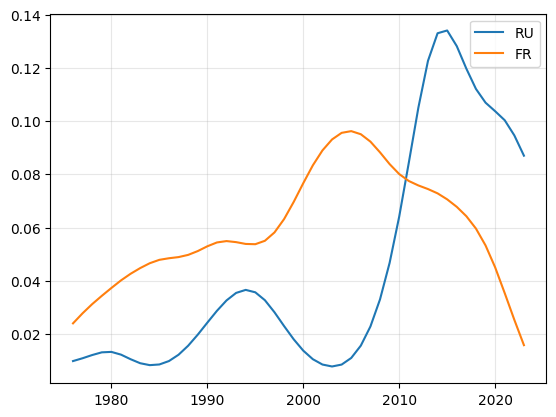

In [234]:
country1 = "RU"
country2 = "FR"

plt.plot(np.array(years_active_country_dict[country1])[1:], s_country_dict[country1], label=country1)
plt.plot(np.array(years_active_country_dict[country2])[1:], s_country_dict[country2], label=country2)
plt.legend()
plt.grid(alpha=0.3)


=== Кривая A ===
n_points: 48
n_kinks: 14
kink_x: [0.021 0.213 0.255 0.298 0.319 0.383 0.447 0.468 0.511 0.553 0.574 0.638
 0.787 0.809]
kink_angle_deg: [ -39.449   37.099   38.111  -33.064   30.828   26.499  -19.965  -34.253
   67.045  -58.958  -52.288   81.431  -37.639 -102.387]
tortuosity L/C: 2.5
total_turning (sum|theta|): 15.102
inflections (sign changes of theta): 15
TV(y) (sum|dy|): 2.457
max|k|: 44.246
mean|k|: 10.125
  вокруг вершины 1: {'k_left_mean': nan, 'k_right_mean': 0.12, 'k_left_nearest': nan, 'k_right_nearest': -6.5, 'kink_angle_deg': -39.45}
  вокруг вершины 10: {'k_left_mean': -3.98, 'k_right_mean': -0.0, 'k_left_nearest': -3.46, 'k_right_nearest': 6.8, 'kink_angle_deg': 37.1}
  вокруг вершины 12: {'k_left_mean': -1.29, 'k_right_mean': -1.07, 'k_left_nearest': 6.8, 'k_right_nearest': 4.56, 'kink_angle_deg': 38.11}
  вокруг вершины 14: {'k_left_mean': 1.52, 'k_right_mean': -0.47, 'k_left_nearest': 4.56, 'k_right_nearest': 24.34, 'kink_angle_deg': -33.06}
  вокруг в

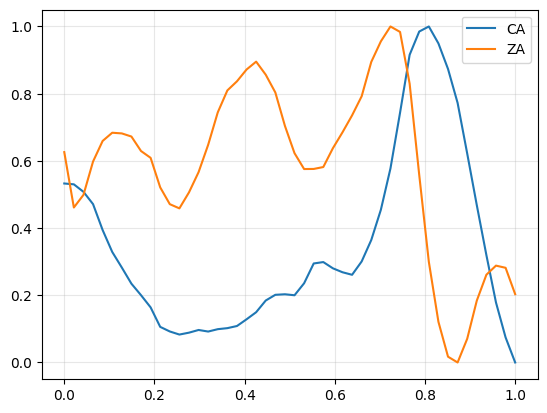

In [30]:
xa = np.array(years_active_country_dict[country1])[1:]
ya = s_country_dict[country1]

xb = np.array(years_active_country_dict[country2])[1:]
yb = s_country_dict[country2]


# общая нормировка для обеих кривых
xr = (min(xa.min(), xb.min()), max(xa.max(), xb.max()))
yr = (min(ya.min(), yb.min()), max(ya.max(), yb.max()))
xa, ya = normalize(xa, ya, (xa.min(), xa.max()), (ya.min(), ya.max()))
xb, yb = normalize(xb, yb, (xb.min(), xb.max()), (yb.min(), yb.max()))

plt.plot(xa, ya, label=country1)
plt.plot(xb, yb, label=country2)
plt.legend()
plt.grid(alpha=0.3)


for name, (x, y) in {"A": (xa, ya), "B": (xb, yb)}.items():
    print(f"\n=== Кривая {name} ===")
    for key, val in passport(x, y, thr_deg=15).items():
        print(f"{key}: {np.round(val, 3)}")
    for v in find_kinks(x, turning_profile(x, y)["theta"], 15):
        print(f"  вокруг вершины {v}:", {k: round(float(c), 2) for k, c in curvature_around(x, y, v).items()})

print("\n=== Сравнение A и B ===")
for key, val in compare(xa, ya, xb, yb).items():
    print(f"{key}: {val:.4f}")

# All countries : novelty based segmentation

In [31]:
df_list_stat = []
df_list_bkps = []

for country in tqdm(country_list):
    try:
        df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
        year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
        if len(year_list_active) <= 20:
            continue
        df_dist_test = df_dist_test.loc[year_list_active, year_list_active]

        stat_dict, df_country_bkps, _ = get_country_bkps(country, df_dist_test, 10)
        
        df_list_stat.append(stat_dict)
        df_list_bkps.append(df_country_bkps)

    except Exception as e:
        print(country, e)

df_n_bkps = pd.json_normalize(df_list_stat)
df_bkps = pd.concat(df_list_bkps)

100%|██████████| 206/206 [00:00<00:00, 438.84it/s]


In [284]:
df_n_bkps

,country,s_median,s_mean,s_min,s_max,s_std,s_unstable,n_bkps,gini,silhouette
0,AE,0.043045,0.021965,0.021965,0.105142,0.024373,0.006237,3,0.375000,0.225513
1,AM,0.149416,0.015002,0.015002,0.212036,0.064014,0.011667,2,0.400000,0.548457
2,AR,0.081083,0.016448,0.016448,0.135045,0.035546,0.008730,2,0.244898,0.515242
3,AT,0.039954,0.028418,0.028418,0.054753,0.006842,0.001977,6,0.355685,0.212347
4,AU,0.034883,0.013452,0.013452,0.049508,0.008337,0.001677,4,0.073469,0.393545
...,...,...,...,...,...,...,...,...,...,...
72,US,0.018016,0.009275,0.009275,0.053925,0.013076,0.002617,5,0.323129,0.279623
73,UZ,0.215631,0.034566,0.034566,0.335598,0.086328,0.028884,2,0.212121,0.615577
74,VE,0.068457,0.024250,0.024250,0.134177,0.028765,0.007356,3,0.107143,0.512329
75,VN,0.037938,0.027573,0.027573,0.137673,0.027048,0.008195,2,0.333333,0.150457


In [285]:
df_plot = (
    df_n_bkps
    .merge(df_country[["alpha2", "alpha-3", "name", "region", "sub-region"]], left_on="country", right_on="alpha2")
    .drop("country", axis=1)
    .rename(columns={"alpha-3": "country"})
    # .query("modularity >= 0")
    
)

In [286]:
# fig = px.choropleth(
#     df_plot,
#     locations="country",
#     # locationmode="country names",
#     color="silhouette",
#     hover_name="country",
#     hover_data=["alpha2", "n_bkps", "gini", "silhouette", "s_min", "s_max", "s_median"],
#     color_continuous_scale="Viridis",
#     projection="natural earth",
# )
# fig.show()

In [287]:
fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="gini",
    hover_name="country",
    hover_data=["alpha2", "n_bkps", "gini", "silhouette", "s_min", "s_max", "s_median"],
    color_continuous_scale="Viridis",
    projection="natural earth",
)
fig.show()

In [288]:
fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="n_bkps",
    hover_name="country",
    hover_data=["alpha2", "n_bkps", "gini", "silhouette", "s_min", "s_max", "s_median"],
    color_continuous_scale="Viridis",
    projection="natural earth",
)
fig.show()

In [289]:
fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="s_median",
    hover_name="country",
    hover_data=["alpha2", "n_bkps", "gini", "silhouette", "s_min", "s_max", "s_median"],
    color_continuous_scale="Viridis",
    projection="natural earth",
)
fig.show()

In [290]:
fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="s_max",
    hover_name="country",
    hover_data=["alpha2", "n_bkps", "gini", "silhouette", "s_min", "s_max", "s_median"],
    color_continuous_scale="Viridis",
    projection="natural earth",
)
fig.show()

In [291]:
fig = px.scatter(df_plot, x="s_median", y="s_max", hover_name="name", hover_data=["alpha2"], color="sub-region")

lo = min(df_plot["s_median"].min(), df_plot["s_max"].min())
hi = max(df_plot["s_median"].max(), df_plot["s_max"].max())
fig.add_shape(type="line", x0=lo, y0=lo, x1=hi, y1=hi,
              line=dict(dash="dash", color="gray"))
fig.show()

In [292]:
px.box(df_plot, x="sub-region", y="s_median", points="all")

In [293]:
px.scatter(df_plot, x="s_median", y="s_max", hover_name="name", hover_data=["alpha2"])

In [294]:
px.scatter(df_plot, x="gini", y="silhouette", hover_name="name")

In [295]:
import numpy as np
import pandas as pd

def pca(df, n_components=None):
    """
    PCA on a DataFrame (rows = samples, columns = features).
    Returns the reduced data as a DataFrame and a dict of stats.
    """
    X = df.select_dtypes(include="number").values
    mu = X.mean(axis=0)
    Xc = X - mu                                   # center each column

    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    k = n_components or min(Xc.shape)

    var = S**2 / (len(X) - 1)                     # variance per component
    ratio = var / var.sum()

    scores = pd.DataFrame(
        Xc @ Vt[:k].T,
        index=df.index,
        columns=[f"PC{i+1}" for i in range(k)],
    )
    stats = {
        "explained_variance": var[:k],
        "explained_variance_ratio": ratio[:k],
        "cumulative_ratio": np.cumsum(ratio)[:k],
        "components": pd.DataFrame(
            Vt[:k].T,
            index=df.select_dtypes(include="number").columns,
            columns=scores.columns,
        ),
        "mean": pd.Series(mu, index=df.select_dtypes(include="number").columns),
    }
    return scores, stats

reduced, stats = pca(df_dist_test, n_components=2)
print(stats["explained_variance_ratio"])

LinAlgError: SVD did not converge

In [296]:
df_plot_years = (
    df_bkps
    .merge(df_country[["alpha2", "alpha-3", "name", "region", "sub-region"]], left_on="country", right_on="alpha2")
    .drop("country", axis=1)
    .rename(columns={"alpha-3": "country"})
    # .sort_values("strength", ascending=False)
    # .drop_duplicates("country")
    # .query("strength > 0.05")
)
df_plot_years

,year,strength,suddenness,prev_period,post_period,alpha2,country,name,region,sub-region
0,2007.0,0.088269,0.012853,4.0,11.0,AE,ARE,United Arab Emirates,Asia,Western Asia
1,2018.0,0.043524,0.005896,11.0,4.0,AE,ARE,United Arab Emirates,Asia,Western Asia
2,2022.0,0.046437,0.004897,4.0,1.0,AE,ARE,United Arab Emirates,Asia,Western Asia
3,2015.0,0.212036,0.021232,17.0,6.0,AM,ARM,Armenia,Asia,Western Asia
4,2021.0,0.159311,0.017950,6.0,2.0,AM,ARM,Armenia,Asia,Western Asia
...,...,...,...,...,...,...,...,...,...,...
238,1976.0,0.043445,0.012745,2.0,6.0,ZA,ZAF,South Africa,Africa,Sub-Saharan Africa
239,1982.0,0.051664,0.000518,6.0,14.0,ZA,ZAF,South Africa,Africa,Sub-Saharan Africa
240,1996.0,0.061584,0.003563,14.0,14.0,ZA,ZAF,South Africa,Africa,Sub-Saharan Africa
241,2010.0,0.067565,0.003459,14.0,11.0,ZA,ZAF,South Africa,Africa,Sub-Saharan Africa


In [298]:
fig = px.choropleth(
    df_plot_years.sort_values("strength", ascending=False).drop_duplicates("country"),
    locations="country",
    # locationmode="country names",
    color="year",
    hover_name="country",
    hover_data=["alpha2", "strength"],
    color_continuous_scale="Viridis",
    projection="natural earth",
)
fig.show()

In [212]:
# px.line(df_plot_years.groupby("year", as_index=False).strength.sum(), x="year", y="strength")

In [213]:
px.scatter(df_plot_years, x="year", y="strength", hover_data=["name", "alpha2"])

In [214]:
px.scatter(df_plot_years, x="alpha2", y="strength", color="sub-region", hover_name="name")

In [215]:
px.box(df_plot_years, x="sub-region", y="strength", color="sub-region", hover_name="name", points="all")